# ПР2. Устойчивость глубокой модели к шуму и естественным искажениям

**Курс:** «Безопасность и доверенность систем ИИ». **Команда:** Андрусенко К.А., Синёв В.Е., Шестакова М.А., гр. 1379.

**Модель:** зафиксированный baseline — FT-Transformer C96 без R2 (`artifacts/baseline_model.pt`); веса и препроцессор не меняются.
**Совокупность:** test без служебных оценок R2. **Метрика M:** RMSLE, меньше — лучше.
ΔM(s) = M(0) − M(s): отрицательное значение — ухудшение; R_rel = M(s)/M(0) > 1 — ухудшение;
R-AUC — средняя RMSLE на диапазоне шума (трапеции, s₀ = 0 входит в кривую), меньше — лучше; R-AUC_rel = R-AUC / M(0).
Исследуется corruption robustness (не adversarial). Расчёты — `src/pr2_noise.py`, план — `docs/context/PLAN_PR2.md`.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
R = ROOT / "reports" / "pr2"
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:.4g}".format)


def show(name, cols=None, query=None, n=None):
    df = pd.read_csv(R / f"{name}.csv")
    if query:
        df = df.query(query)
    if cols:
        df = df[cols]
    display(df.head(n) if n else df)
    return df


def img(name, width=None):
    display(Image(filename=str(R / f"{name}.png"), width=width))

## 1. Baseline M(0)

M(0) пересчитан кодом ПР2 по сохранённому прогнозу на чистом test и сверен с `baseline_metrics.json`
(столбец `matches_baseline`); прогноз на чистом test, полученный через весь путь искажения при s = 0, совпал с baseline бит-в-бит
(проверка в журнале `artifacts/logs/pr2_noise.log`).

In [2]:
show("baseline");

,metric,value,ci_low,ci_high,ci_method,n,B,baseline_metrics_json,matches_baseline
0,RMSLE,0.8885,0.8834,0.8949,BCa,96952,2000,0.8885,True
1,"MdAPE, %",53.51,53.15,53.97,BCa,96952,2000,53.51,True
2,доля в ±25%,0.2545,0.2517,0.2572,wilson,96952,NaN,0.2545,True
3,доля в ±25% (bootstrap),0.2545,0.2516,0.2571,BCa,96952,2000,0.2545,True


## 2. Модель шума

Четыре типа искажений, по два на модальность; общая сетка s ∈ {0; 0,1; 0,2; 0,3; 0,4; 0,5}, r = 5 независимых реализаций
на уровень (seed = 42 + 1000·t + 100·k + j). Шум накладывается на исходные столбцы test до препроцессора.

| # | Модальность | Искажение | s |
|---|---|---|---|
| T1 | таблица | пропуски (MCAR): площадь, высота, DU/ADU, координаты (lat и lon вместе), все категории, кроме PERMIT_TYPE | доля стёртых значений |
| T2 | таблица | порча категорий: непустая категория → случайное значение по частотам train | доля заменённых категорий |
| X1 | текст | опечатки: одна символьная ошибка в слове из ≥ 3 букв (перестановка, удаление, вставка, соседняя клавиша) | доля слов с опечаткой |
| X2 | текст | удаление слов (токенов модели) | доля удалённых слов |

`frac_selected` — доля выбранных значений (≈ s), `frac_changed` — фактически изменённых: у T1 уже пустые ячейки не меняются,
у T2 случайная категория может совпасть с исходной, у X1 перестановка одинаковых букв ничего не меняет.

In [3]:
show("noise_grid", ["type", "name", "level", "eligible_unit", "eligible", "frac_selected", "frac_changed", "frac_changed_of_words", "rmsle_real_min", "rmsle_real_max", "rmsle_real_std"]);

,type,name,level,eligible_unit,eligible,frac_selected,frac_changed,frac_changed_of_words,rmsle_real_min,rmsle_real_max,rmsle_real_std
0,T1,Пропуски (MCAR),0.1,все ячейки затрагиваемых признаков,1.842e+06,0.1001,0.07458,NaN,0.9147,0.9157,0.0005019
1,T1,Пропуски (MCAR),0.2,все ячейки затрагиваемых признаков,1.842e+06,0.2,0.1489,NaN,0.9425,0.9456,0.001114
2,T1,Пропуски (MCAR),0.3,все ячейки затрагиваемых признаков,1.842e+06,0.2999,0.2233,NaN,0.9755,0.9798,0.001565
3,T1,Пропуски (MCAR),0.4,все ячейки затрагиваемых признаков,1.842e+06,0.3997,0.2976,NaN,1.013,1.016,0.001343
4,T1,Пропуски (MCAR),0.5,все ячейки затрагиваемых признаков,1.842e+06,0.4998,0.3722,NaN,1.055,1.057,0.0008344
5,T2,Порча категорий,0.1,непустые категории,1.204e+06,0.0997,0.06949,NaN,0.8996,0.9007,0.0004807
6,T2,Порча категорий,0.2,непустые категории,1.204e+06,0.1997,0.139,NaN,0.9111,0.9145,0.001282
7,T2,Порча категорий,0.3,непустые категории,1.204e+06,0.3,0.2089,NaN,0.9263,0.9279,0.0007034
8,T2,Порча категорий,0.4,непустые категории,1.204e+06,0.4,0.2786,NaN,0.9394,0.9425,0.001172
9,T2,Порча категорий,0.5,непустые категории,1.204e+06,0.5001,0.3485,NaN,0.9548,0.957,0.00101


Выбранная доля значений совпадает с заданной s (при s = 0,5: 0,4998 у T1, 0,5001 у T2). Фактически изменено меньше:
у T1 при s = 0,5 стёрто 0,3722 ячеек (около четверти ячеек test уже пусты — ПР1), у T2 изменено 0,3485 категорий
(случайное значение по частотам train часто совпадает с исходным, у флагов HL/EV — почти всегда).
У X1 опечатку получили 0,4917 слов из ≥ 3 букв, т. е. 0,3595 всех слов; у X2 удалено ровно s слов.
Разброс RMSLE между реализациями шума мал (std ≤ 0,0018) — на порядок меньше эффектов, r = 5 достаточно.

## 3. Robustness curves

Коридор — 95% CI (парный bootstrap по объектам: одни и те же перевыборки для clean и всех точек, B = 2000, percentile).
Ошибка объекта на уровне s — средний квадрат лог-ошибки по r реализациям. Пунктир — естественный уровень искажения по ПР1.

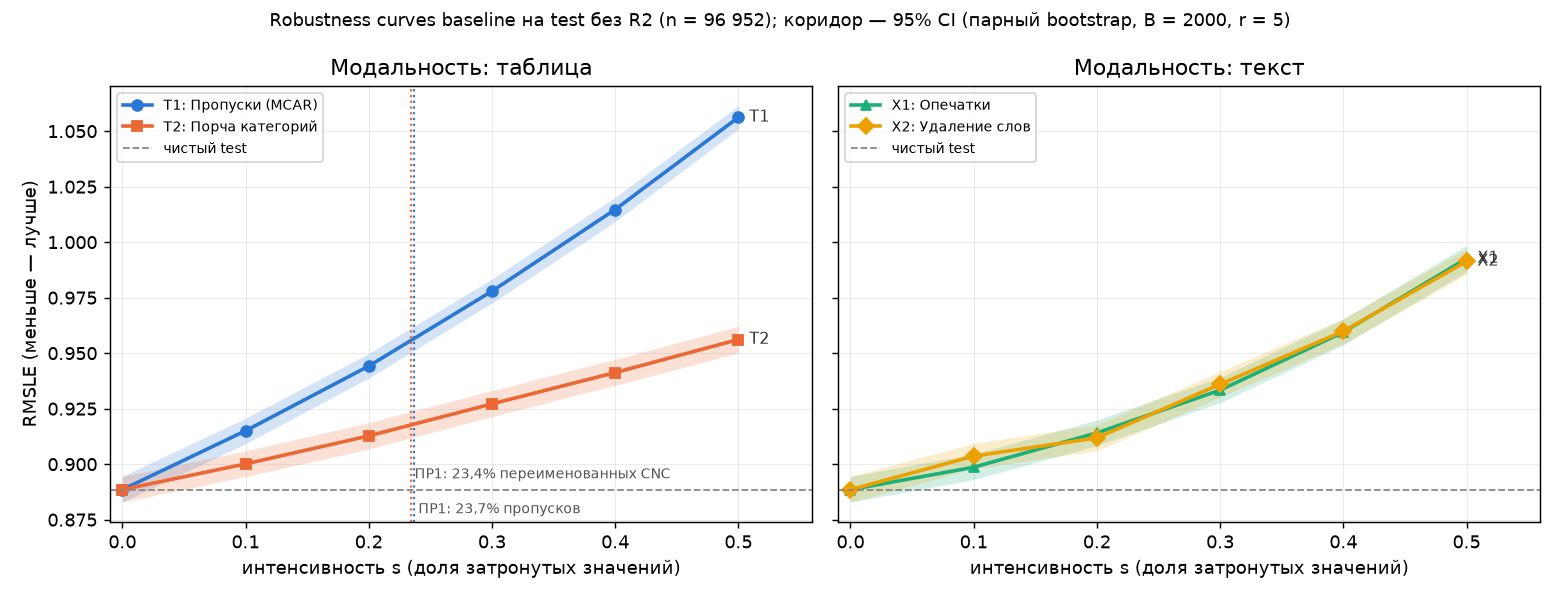

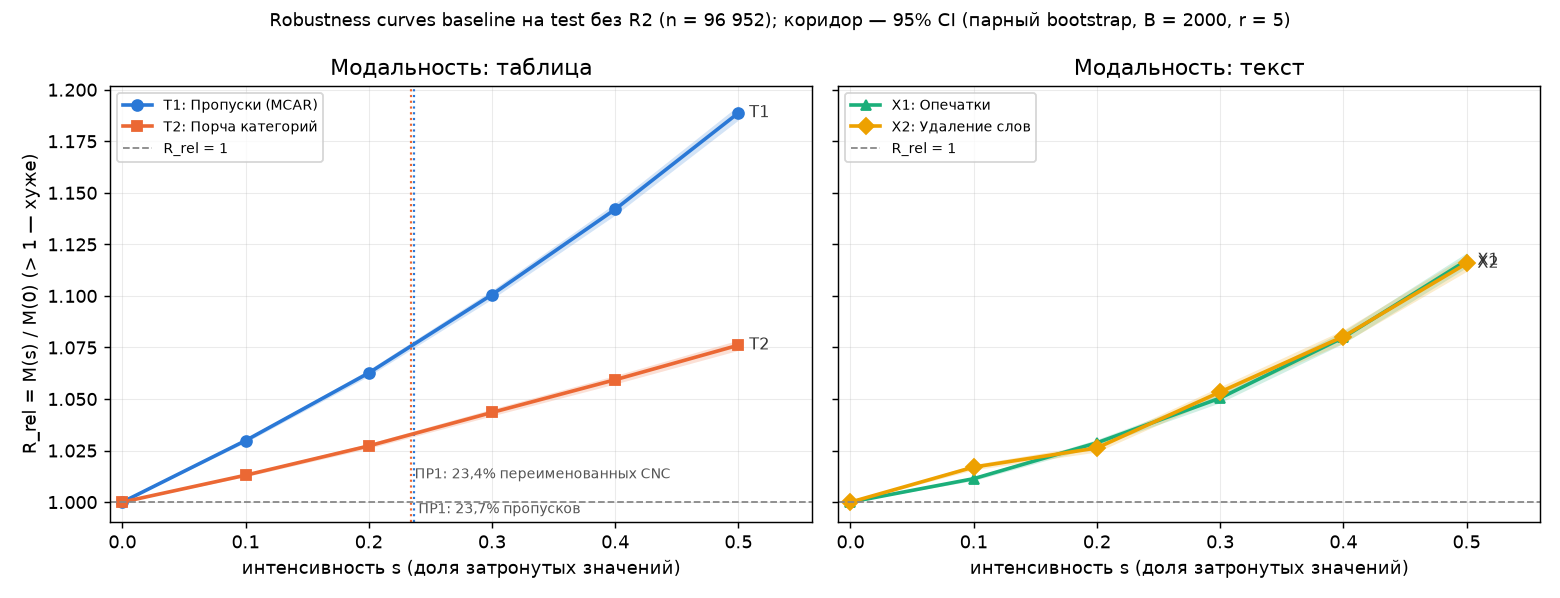

In [4]:
img("curves_rmsle")
img("curves_rel")

In [5]:
show("curves", ["type", "level", "frac_changed", "rmsle", "rmsle_low", "rmsle_high", "delta", "delta_low", "delta_high", "significant", "practical", "r_rel", "mdape", "delta_mdape", "within25", "delta_within25"]);

,type,level,frac_changed,rmsle,rmsle_low,rmsle_high,delta,delta_low,delta_high,significant,practical,r_rel,mdape,delta_mdape,within25,delta_within25
0,T1,0,0,0.8885,0.8829,0.8945,0,0,0,False,False,1,53.51,0,0.2545,0
1,T1,0.1,0.07458,0.915,0.9092,0.9207,-0.02651,-0.02725,-0.02576,True,True,1.03,55.4,-1.893,0.2448,-0.009656
2,T1,0.2,0.1489,0.9442,0.9388,0.9499,-0.05566,-0.05687,-0.05447,True,True,1.063,57.41,-3.903,0.2334,-0.02102
3,T1,0.3,0.2233,0.9779,0.9726,0.9835,-0.0894,-0.09102,-0.08775,True,True,1.101,59.81,-6.305,0.2225,-0.03193
4,T1,0.4,0.2976,1.015,1.009,1.02,-0.1262,-0.1283,-0.1241,True,True,1.142,62.37,-8.859,0.2116,-0.04285
5,T1,0.5,0.3722,1.056,1.051,1.062,-0.1677,-0.1703,-0.1653,True,True,1.189,64.92,-11.41,0.2006,-0.05384
6,T2,0,0,0.8885,0.8829,0.8945,0,0,0,False,False,1,53.51,0,0.2545,0
7,T2,0.1,0.06949,0.9001,0.8944,0.906,-0.01159,-0.01221,-0.01097,True,False,1.013,54.02,-0.512,0.2519,-0.002597
8,T2,0.2,0.139,0.9127,0.9068,0.9187,-0.02421,-0.02522,-0.02319,True,True,1.027,54.58,-1.066,0.2494,-0.005095
9,T2,0.3,0.2089,0.9272,0.9215,0.9332,-0.03863,-0.04003,-0.03723,True,True,1.043,55.07,-1.563,0.246,-0.008452


- **Все четыре кривые монотонно растут; ухудшение статистически значимо уже при s = 0,1** у каждого типа (CI ΔM не содержит 0).
  Практическую значимость оцениваем относительно разброса RMSLE между seed обучения (≈ 0,01) и порога 0,02, принятого в экспериментах.
- **T1 (пропуски)** — самый сильный эффект: ΔM = −0,0265 [−0,0273; −0,0258] уже при s = 0,1 (выше порога 0,02),
  при s = 0,5 — −0,1677, RMSLE 1,0562, R_rel 1,189. Естественная доля пропусков в данных (23,7%, ПР1) лежит между уровнями
  0,2 и 0,3, где ΔM от −0,0557 до −0,0894 (здесь s — пропуски сверх уже имеющихся).
- **T2 (порча категорий)** — слабее всех: при s = 0,1 ΔM = −0,0116 (порядка разброса между seed), порог 0,02 превышен
  с s = 0,2 (−0,0242), при s = 0,5 — −0,0676.
- **X1 и X2 (текст)** почти совпадают: при s = 0,1 ΔM = −0,0101 и −0,0151 (меньше порога 0,02), с s = 0,2 — практически
  значимо (−0,0256 и −0,0233), при s = 0,5 — −0,1041 и −0,1028. Кривые выпуклые: малый текстовый шум модель переносит,
  дальше ухудшение ускоряется.
- **MdAPE и доля в ±25%** у T1, T2, X1 ухудшаются вместе с RMSLE (T1 при s = 0,5: MdAPE 64,92% против 53,51%,
  ΔMdAPE −11,41 п.п.; доля в ±25% −0,0538). **У X2 — наоборот:** MdAPE улучшается (+4,72 п.п. при s = 0,2), доля в ±25%
  растёт на 0,0156, хотя RMSLE хуже. Это не устойчивость, а сдвиг прогноза вниз, частично компенсирующий завышение
  baseline на мелких разрешениях (раздел 6).

## 4. R-AUC

Для каждой bootstrap-перевыборки кривая восстанавливается целиком и считается площадь (трапеции, s ∈ [0; 0,5]).
`rauc_minus_m0` — среднее ухудшение RMSLE на диапазоне шума.

In [6]:
show("rauc", ["type", "name", "rauc", "rauc_low", "rauc_high", "rauc_rel", "rauc_rel_low", "rauc_rel_high", "rauc_minus_m0", "rauc_minus_m0_low", "rauc_minus_m0_high"]);

,type,name,rauc,rauc_low,rauc_high,rauc_rel,rauc_rel_low,rauc_rel_high,rauc_minus_m0,rauc_minus_m0_low,rauc_minus_m0_high
0,T1,Пропуски (MCAR),0.9648,0.9595,0.9704,1.086,1.084,1.088,0.07632,0.07514,0.07753
1,T2,Порча категорий,0.9207,0.9149,0.9267,1.036,1.035,1.037,0.0322,0.03122,0.03317
2,X1,Опечатки,0.9292,0.9237,0.9349,1.046,1.044,1.048,0.0407,0.03926,0.04217
3,X2,Удаление слов,0.9303,0.9246,0.936,1.047,1.045,1.049,0.04174,0.04012,0.04336


Ранжирование по R-AUC_rel (больше — хуже): **T1 1,0859** [1,0843; 1,0875] → X2 1,0470 → X1 1,0458 → **T2 1,0362**
[1,0351; 1,0374]. В единицах RMSLE: R-AUC у T1 0,9648 [0,9595; 0,9704] против M(0) 0,8885, т. е. среднее ухудшение на диапазоне
шума 0,0763; у текстовых типов 0,0417 (X2) и 0,0407 (X1), у T2 0,0322. Интервалы X1 и X2 перекрываются
([0,0393; 0,0422] и [0,0401; 0,0434]); парного сравнения X1 с X2 не делали, поэтому порядок между ними не утверждаем.

## 5. Подгруппы

ΔM по типу разрешения и наличию площади (все типы шума) и по длине описания и обрезке текста (X1, X2) при s = 0,2 и 0,4;
bootstrap внутри группы.

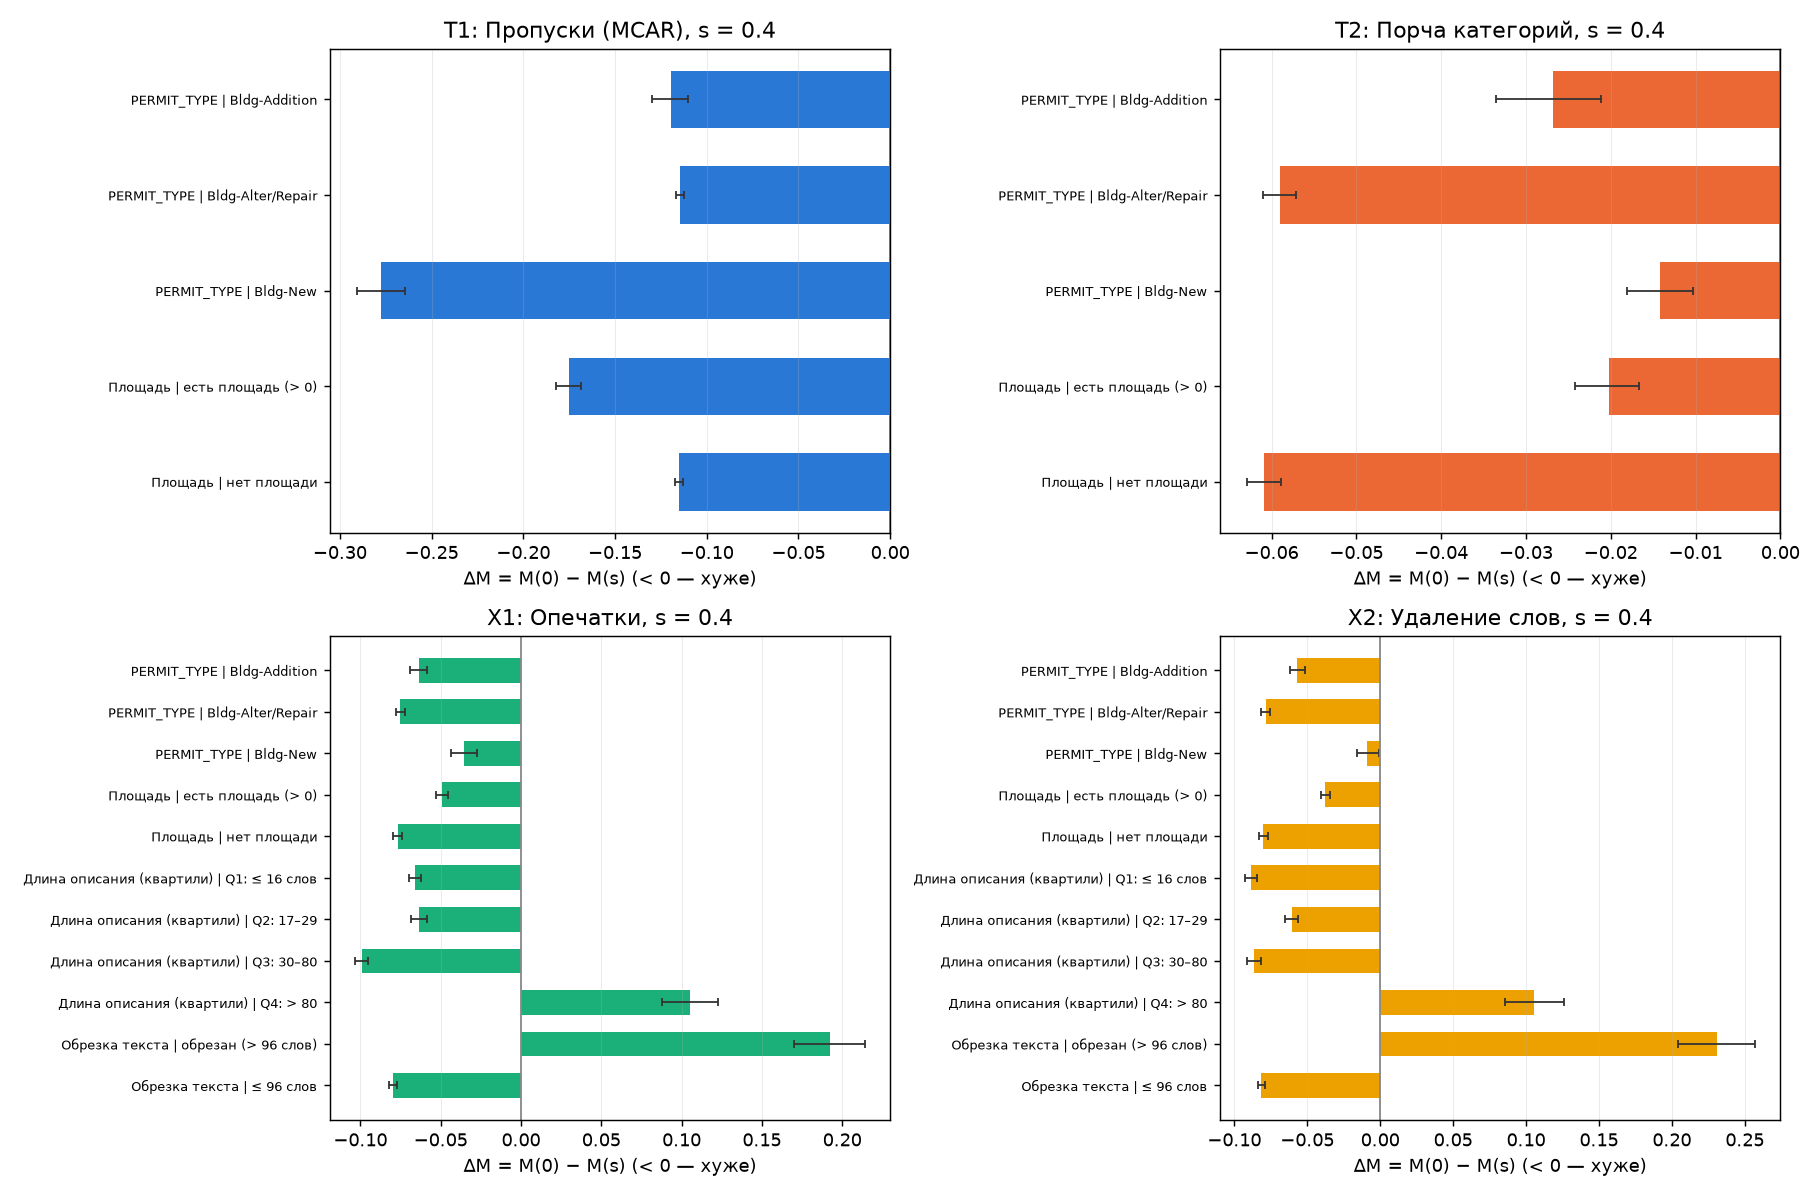

,type,level,grouping,group,n,rmsle0,rmsle,delta,delta_low,delta_high,significant
0,T1,0.2,PERMIT_TYPE,Bldg-Addition,10938,0.6948,0.749,-0.05426,-0.05927,-0.04973,True
1,T1,0.4,PERMIT_TYPE,Bldg-Addition,10938,0.6948,0.8142,-0.1194,-0.1298,-0.1101,True
2,T2,0.2,PERMIT_TYPE,Bldg-Addition,10938,0.6948,0.7069,-0.01211,-0.01485,-0.009404,True
3,T2,0.4,PERMIT_TYPE,Bldg-Addition,10938,0.6948,0.7216,-0.0268,-0.03356,-0.02112,True
4,X1,0.2,PERMIT_TYPE,Bldg-Addition,10938,0.6948,0.7196,-0.02479,-0.02794,-0.02171,True
...,...,...,...,...,...,...,...,...,...,...,...
59,X2,0.4,Обрезка текста,обрезан (> 96 слов),2280,1.367,1.137,0.2306,0.2043,0.2569,True
60,X1,0.2,Обрезка текста,≤ 96 слов,94672,0.8738,0.9043,-0.03049,-0.03185,-0.02921,True
61,X1,0.4,Обрезка текста,≤ 96 слов,94672,0.8738,0.9537,-0.0799,-0.08227,-0.07751,True
62,X2,0.2,Обрезка текста,≤ 96 слов,94672,0.8738,0.9013,-0.02749,-0.02906,-0.02583,True


In [7]:
img("delta_by_group")
show("by_group", ["type", "level", "grouping", "group", "n", "rmsle0", "rmsle", "delta", "delta_low", "delta_high", "significant"]);

- **Пропуски (T1) сильнее всего бьют по новому строительству**: при s = 0,4 у Bldg-New ΔM = −0,2775 (R_rel 1,475) против
  −0,1145 у Alter/Repair и −0,1194 у Addition; у разрешений с площадью −0,1753 против −0,1151 без неё.
  Стоимость нового здания модель определяет по площади и назначению — без них ошибка растёт быстрее всего.
- **Порча категорий и текст, наоборот, почти не задевают Bldg-New** (при s = 0,4: T2 −0,0142, X2 −0,0090; у X2 при s = 0,2 CI
  содержит 0: [−0,0093; 0,0001]) и сильнее всего бьют по Alter/Repair (T2 −0,0590, X1 −0,0752, X2 −0,0784): у ремонтов нет
  площади, и описание работ — главный источник информации о масштабе.
- **На длинных описаниях шум снижает RMSLE**: у обрезанных текстов (> 96 слов, n = 2280) при s = 0,4 ΔM = +0,1921 (X1)
  и +0,2306 (X2), у квартиля Q4 (> 80 слов) — +0,1052. Это не устойчивость: на таких разрешениях baseline сильно завышает
  стоимость, а шум снижает прогноз (раздел 6).

## 6. Сдвиг прогноза под шумом

Средний остаток log1p(прогноз) − log1p(факт), > 0 — завышение; по всем строкам, по квартилям VALUATION и для обрезанных описаний.
Таблица — уровни 0; 0,2; 0,5 (полная — `bias.csv`).

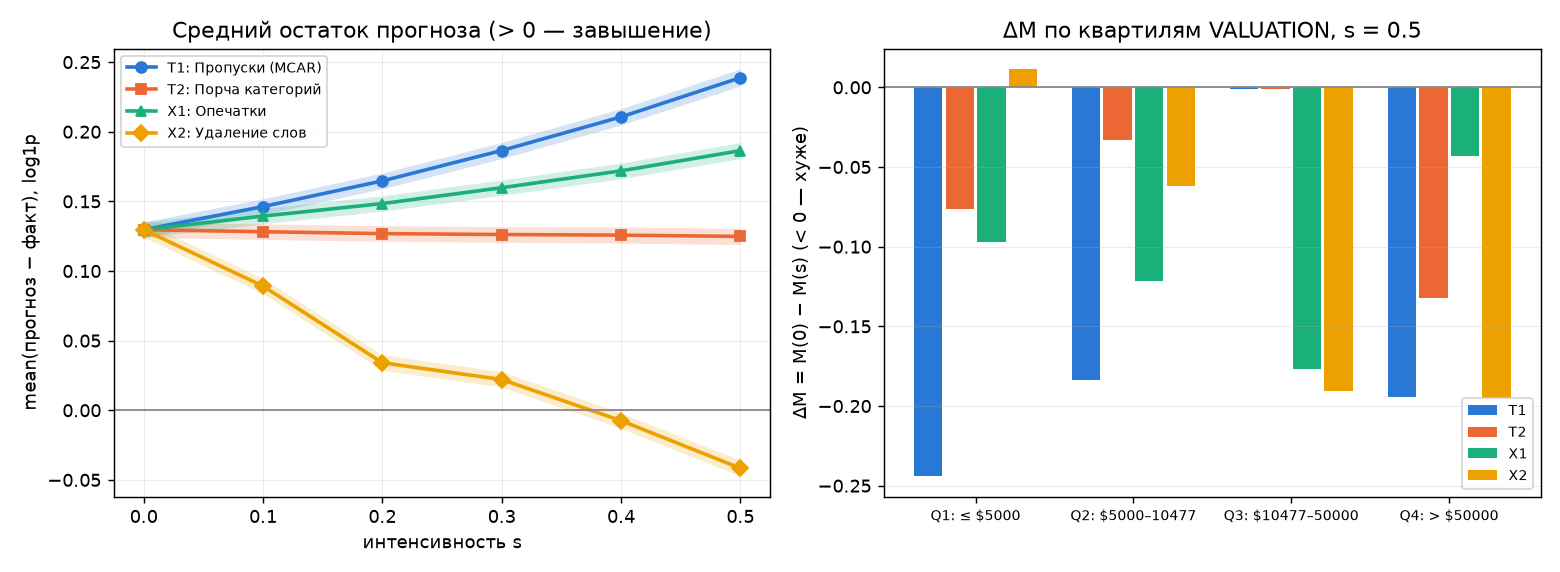

,type,level,grouping,group,n,bias,bias_low,bias_high,delta_bias,rmsle,delta
0,T1,0,Все,все,96952,0.1296,0.1242,0.1352,0,0.8885,0
2,T1,0.2,Все,все,96952,0.1647,0.1591,0.1704,0.03507,0.9442,-0.05566
5,T1,0.5,Все,все,96952,0.2388,0.2329,0.2451,0.1092,1.056,-0.1677
6,T1,0,Квартиль VALUATION,Q1: ≤ $5000,28521,0.7966,0.7885,0.8048,0,1.068,0
8,T1,0.2,Квартиль VALUATION,Q1: ≤ $5000,28521,0.8824,0.8742,0.8904,0.08588,1.141,-0.0725
...,...,...,...,...,...,...,...,...,...,...,...
122,X2,0.2,Квартиль VALUATION,Q4: > $50000,23553,-0.5369,-0.548,-0.5257,-0.06611,1.025,-0.06588
125,X2,0.5,Квартиль VALUATION,Q4: > $50000,23553,-0.66,-0.6715,-0.6478,-0.1892,1.154,-0.195
126,X2,0,Обрезка текста,обрезан (> 96 слов),2280,0.6061,0.5546,0.6572,0,1.367,0
128,X2,0.2,Обрезка текста,обрезан (> 96 слов),2280,0.436,0.3877,0.4844,-0.1701,1.277,0.09062


In [8]:
img("bias_curves")
show("bias", ["type", "level", "grouping", "group", "n", "bias", "bias_low", "bias_high", "delta_bias", "rmsle", "delta"], query="level in [0, 0.2, 0.5]");

- **Baseline прижимает прогноз к среднему:** мелкие разрешения завышает (Q1 ≤ $5000: средний остаток +0,7966), крупные занижает
  (Q4 > $50000: −0,4708); в среднем +0,1296 — то самое смещение вверх, найденное при переобучении без R2.
- **Табличный шум усиливает этот эффект** (меньше информации — прогноз ближе к среднему): при s = 0,5 у T1 остаток в Q1
  +1,0685, в Q4 −0,5738; у T2 +0,8864 и −0,5985. Поэтому теряют точность крайние квартили (T1: Q1 ΔM −0,2440, Q4 −0,1945),
  а Q3 почти не меняется (−0,0009).
- **Удаление слов (X2) сдвигает вниз все прогнозы** (короче описание — «меньше работ»): средний остаток 0,1296 → 0,0341
  (s = 0,2) → −0,0417 (s = 0,5). На мелких разрешениях это частично гасит завышение (Q1: RMSLE лучше, ΔM +0,0362 при s = 0,2),
  а MdAPE и доля в ±25% определяются в основном мелкими и средними разрешениями — отсюда их «улучшение»; на крупных
  ошибка растёт (Q4 −0,1950 при s = 0,5).
- **Опечатки (X1)** сдвигают прогноз вверх в основном у крупных разрешений (Q4: −0,4708 → −0,3395 при s = 0,5), и сильнее
  всего ухудшают Q3 (ΔM −0,1766).
- На обрезанных описаниях baseline завышает на +0,6061; при удалении половины слов остаток −0,0185, RMSLE 1,3674 → 1,1385.

Вывод: «улучшения» под шумом (MdAPE у X2, длинные тексты) — следствие смещения baseline, а не устойчивости модели.

## 7. Профиль по признакам

T1 и T2 при s = 0,3: портится одна группа признаков, остальное чистое; для сравнения — порча всех признаков типа.

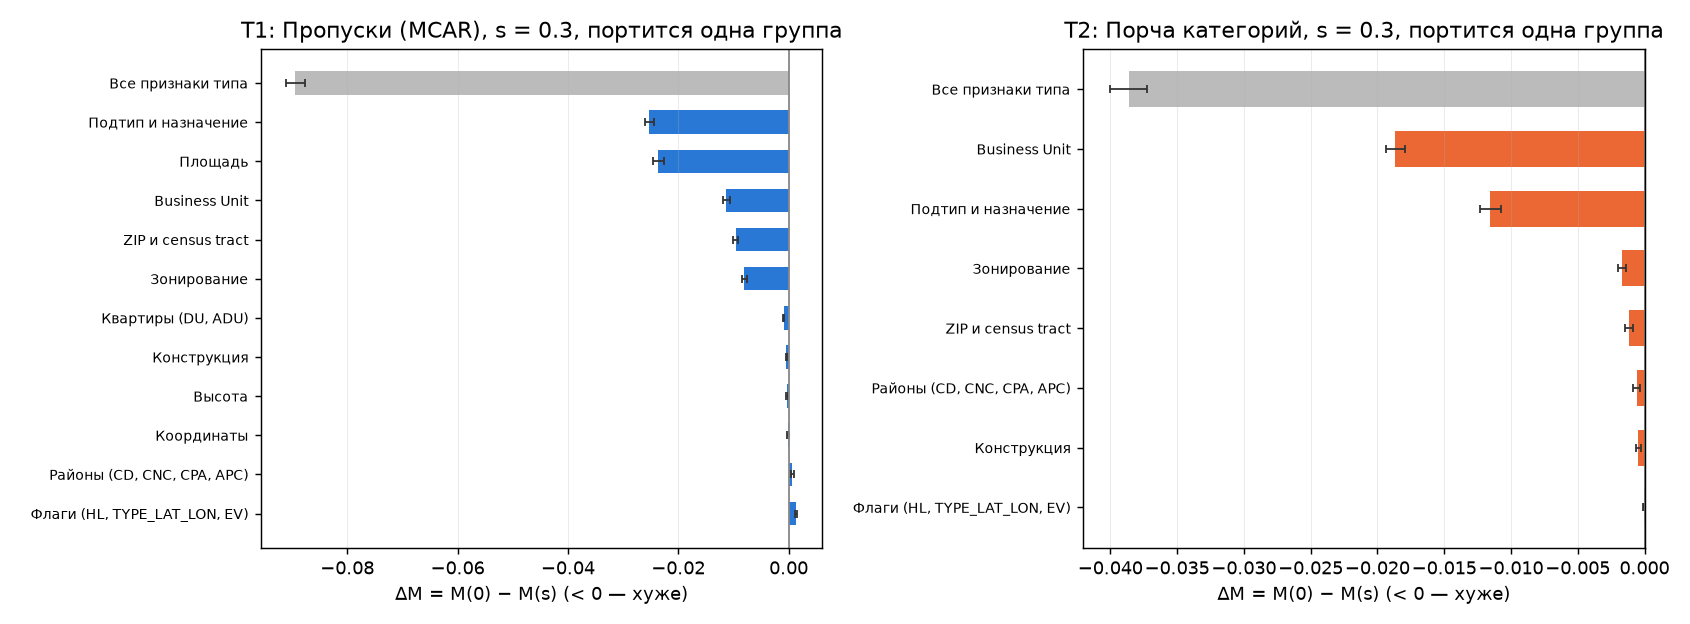

,type,group,columns,frac_changed,rmsle,delta,delta_low,delta_high,significant,rank
0,T1,Все признаки типа,все,0.2233,0.9779,-0.0894,-0.09102,-0.08775,True,NaN
1,T1,Подтип и назначение,"['PERMIT_SUB_TYPE', 'USE_DESC']",0.2999,0.9138,-0.02528,-0.02611,-0.02443,True,1
2,T1,Площадь,['square_footage'],0.08629,0.9121,-0.0236,-0.02462,-0.02264,True,2
3,T1,Business Unit,['Business Unit'],0.2991,0.8998,-0.0113,-0.0119,-0.01068,True,3
4,T1,ZIP и census tract,"['ZIP_CODE', 'CT']",0.2998,0.8981,-0.009594,-0.01008,-0.009128,True,4
5,T1,Зонирование,['ZONE'],0.3002,0.8966,-0.008036,-0.008442,-0.007621,True,5
6,T1,"Квартиры (DU, ADU)","['du_changed', 'adu_changed']",0.04367,0.8894,-0.0009261,-0.00111,-0.0007598,True,6
7,T1,Конструкция,['CONSTRUCTION'],0.08582,0.8889,-0.0003903,-0.000538,-0.0002441,True,7
8,T1,Высота,['height'],0.04633,0.8889,-0.0003464,-0.0004818,-0.0002001,True,8
9,T1,Координаты,['lat+lon'],0.2992,0.8887,-0.0001493,-0.0003791,9.12e-05,False,9


In [9]:
img("by_feature")
show("by_feature", ["type", "group", "columns", "frac_changed", "rmsle", "delta", "delta_low", "delta_high", "significant", "rank"]);

- **T1:** важнее всего пропуски подтипа и назначения (ΔM −0,0253) и площади (−0,0236 — хотя фактически стёрто лишь 0,0863
  ячеек: площадь заполнена у меньшинства разрешений), затем Business Unit (−0,0113), ZIP и census tract (−0,0096),
  зона (−0,0080). Пропуск высоты, квартир, конструкции и координат почти не влияет (по модулю ≤ 0,0009; у координат CI
  содержит 0), а пропуск районов и флагов даже немного снижает RMSLE (+0,0007 и +0,0013).
  Все признаки сразу дают −0,0894 — больше по модулю, чем сумма эффектов отдельных групп: пропуски усиливают друг друга.
- **T2:** почти весь эффект — Business Unit (−0,0187; это порядок рассмотрения заявки — экспресс-разрешение, проверка
  у стойки, полная проверка проекта, т. е. косвенно масштаб работ) и подтип с назначением (−0,0115). Порча географии
  (зона, ZIP/CT, районы) — не больше 0,0017 по модулю: модель почти не опирается на районы, поэтому переименование CNC
  (сдвиг из ПР1) для неё малоопасно.

## 8. Итог

In [10]:
show("summary");

,Тип,Модальность,Искажение,R-AUC (RMSLE),95% CI,R-AUC_rel,95% CI rel,M(s_max),ΔM(s_max) [95% CI],Значимо с s,"ΔM ≤ −0,02 с s",Вывод
0,baseline,—,нет (чистый test),0.8885,[0.8834; 0.8949] (BCa),1,—,—,—,—,—,M(0) — RMSLE на чистом test без R2
1,T1,таблица,Пропуски (MCAR),0.9648,[0.9595; 0.9704],1.086,[1.0843; 1.0875],1.0562 (s = 0.5),-0.1677 [-0.1703; -0.1653],0.1,0.1,место 1 из 4 по R-AUC_rel; практически значимое ухудшение (ΔM ≤ −0.02) с s = 0.1
2,T2,таблица,Порча категорий,0.9207,[0.9149; 0.9267],1.036,[1.0351; 1.0374],0.9561 (s = 0.5),-0.0676 [-0.0698; -0.0655],0.1,0.2,место 4 из 4 по R-AUC_rel; практически значимое ухудшение (ΔM ≤ −0.02) с s = 0.2
3,X1,текст,Опечатки,0.9292,[0.9237; 0.9349],1.046,[1.0441; 1.0476],0.9926 (s = 0.5),-0.1041 [-0.1072; -0.1012],0.1,0.2,место 3 из 4 по R-AUC_rel; практически значимое ухудшение (ΔM ≤ −0.02) с s = 0.2
4,X2,текст,Удаление слов,0.9303,[0.9246; 0.9360],1.047,[1.0451; 1.0489],0.9914 (s = 0.5),-0.1028 [-0.1061; -0.0997],0.1,0.2,место 2 из 4 по R-AUC_rel; практически значимое ухудшение (ΔM ≤ −0.02) с s = 0.2


### Выводы

1. **Самый критичный тип — пропуски во входных признаках (T1):** R-AUC_rel 1,0859, ухудшение практически значимо уже при
   s = 0,1 (ΔM −0,0265), при s = 0,5 RMSLE растёт до 1,0562 (R_rel 1,189). Критичнее всего пропуск подтипа/назначения и площади;
   сильнее всего страдает новое строительство (Bldg-New: R_rel 1,475 при s = 0,4).
2. **Текстовые искажения (X1, X2) — второе место**, между собой не различимы: до s = 0,1 ухудшение меньше 0,02,
   с s = 0,2 — практически значимо, при s = 0,5 около +0,10 RMSLE. Уязвимее всего ремонты (Alter/Repair), где описание —
   главный источник информации.
3. **Порча категорий (T2) — наименее критична** (R-AUC_rel 1,0362, практически значимо с s = 0,2); почти весь эффект дают
   Business Unit и подтип/назначение, порча географии не важна.
4. **Шум смещает прогноз**: табличный — к среднему, удаление слов — вниз. Поэтому вспомогательные метрики под шумом могут
   «улучшаться» (MdAPE у X2), и для вывода об устойчивости нужна основная метрика RMSLE и разбор по квартилям стоимости.
5. **Практически:** перед прогнозом стоит проверять заполненность площади, подтипа/назначения и Business Unit и при их отсутствии
   помечать прогноз как ненадёжный; если модель когда-либо будут переобучать, — добавить аугментацию пропусками
   (в ПР1–ПР4 baseline не меняется).

### Ограничения

- Числовые признаки (площадь, координаты) испорчены только пропусками: шум измерений и округление не исследовались (решение 2026-11-10).
- Клиппинг по квантилям train, замена редких категорий на OTHER и эмбеддинг «пропуск» — часть модели; их сглаживающее
  действие входит в измеряемую устойчивость.
- Шум MCAR и равновероятные опечатки — упрощение: реальные пропуски структурные (ПР1), реальные опечатки неравномерны.
- Профиль по признакам — только при s = 0,3; подгруппы — при s = 0,2 и 0,4; X1 и X2 напрямую (парно) не сравнивались.
- Оценка — только test без R2 (более поздний период со сдвигом относительно train, ПР1); устойчивость на других периодах не проверялась.